<a href="https://colab.research.google.com/github/ksrivithya/EGFR-QSAR-Portfolio/blob/main/EGFR_Bioactivity_QSAR_Portfolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# End-to-End Cheminformatics QSAR Pipeline: EGFR Kinase Bioactivity Modeling

**Author:** Chemistry AI & Cheminformatics Portfolio Project  
**Pipeline Architecture:** Data Acquisition (ChEMBL API) $\rightarrow$ Assay Curation & $p\text{IC}_{50}$ Scaling $\rightarrow$ Lipinski ADME Filtering $\rightarrow$ PAINS Substructure Sanitization $\rightarrow$ Morgan Fingerprints (ECFP4) $\rightarrow$ Bemis-Murcko Scaffold Split $\rightarrow$ Random Forest QSAR Modeling & Prospective Screening

---

### Project Objective
This self-contained notebook demonstrates a production-grade ligand-based virtual screening workflow targeting **Epidermal Growth Factor Receptor (EGFR, ChEMBL203)**—a clinically validated oncology target. Unlike naive random-split toy models, this pipeline implements strict medicinal chemistry data hygiene (PAINS removal, unit standardization) and **Bemis-Murcko scaffold splitting** to prevent analog data leakage and evaluate true chemical generalization.

## Step 1: Environment Setup & Dependency Installation
Install `rdkit` for cheminformatics operations and `chembl_webresource_client` for programmatic retrieval of experimental bioactivity data.

In [3]:
!pip install -q rdkit chembl_webresource_client scikit-learn pandas matplotlib seaborn

## Step 2: Live Bioactivity Data Acquisition (ChEMBL API)
Query the ChEMBL REST API for human **EGFR (`CHEMBL203`)** single-protein inhibition records measured strictly via exact $\text{IC}_{50}$ values (`standard_relation == '='`) in nanomolar (`nM`) units.

In [7]:
import time

target_chembl_id = "CHEMBL203"  # Human EGFR
print(f"Fetching IC50 records for {target_chembl_id} from ChEMBL REST API...")

headers = {"User-Agent": "Mozilla/5.0 (Cheminformatics-QSAR-Pipeline)"}
records = []
limit = 500

for offset in range(0, 2500, limit):
    url = (
        f"https://www.ebi.ac.uk/chembl/api/data/activity.json?"
        f"target_chembl_id={target_chembl_id}&standard_type=IC50"
        f"&standard_relation=%3D&standard_units=nM&limit={limit}&offset={offset}"
    )
    for attempt in range(3):
        try:
            resp = requests.get(url, headers=headers, timeout=20)
            if resp.status_code == 200 and resp.text.strip():
                data = resp.json()
                records.extend(data.get("activities", []))
                print(f"  Batch offset {offset}: fetched {len(records)} records...")
                break
        except Exception:
            time.sleep(2)

if len(records) > 0:
    df_raw = pd.DataFrame(records)[["molecule_chembl_id", "canonical_smiles", "standard_value"]]
else:
    # Reliable mirror fallback if EBI ChEMBL API is temporarily down for maintenance
    print("ChEMBL API busy — loading curated EGFR benchmark dataset from mirror...")
    mirror_url = "https://raw.githubusercontent.com/volkamerlab/teachopencadd/master/teachopencadd/talktorials/T001_query_chembl/data/EGFR_compounds.csv"
    df_mirror = pd.read_csv(mirror_url)
    df_raw = df_mirror.rename(columns={"smiles": "canonical_smiles", "IC50": "standard_value"})[
        ["molecule_chembl_id", "canonical_smiles", "standard_value"]
    ]

print(f"\nSuccess! Loaded {len(df_raw)} bioactivity records.")
df_raw.head()

Fetching IC50 records for CHEMBL203 from ChEMBL REST API...
  Batch offset 0: fetched 500 records...
  Batch offset 500: fetched 1000 records...
  Batch offset 1000: fetched 1500 records...
  Batch offset 1500: fetched 2000 records...
  Batch offset 2000: fetched 2500 records...

Success! Loaded 2500 bioactivity records.


,molecule_chembl_id,canonical_smiles,standard_value
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0
1,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,300.0
2,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7820.0
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0
4,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,40.0


## Step 3: Assay Curation, Deduplication & $p\text{IC}_{50}$ Transformation
1. Remove missing or non-positive $\text{IC}_{50}$ entries.
2. Aggregate duplicate measurements per compound using the **median** $\text{IC}_{50}$ to reduce inter-assay noise.
3. Convert nanomolar $\text{IC}_{50}$ to linear $p\text{IC}_{50}$:
$$p\text{IC}_{50} = -\log_{10}(\text{IC}_{50} \times 10^{-9})$$

In [8]:
df = df_raw.dropna(subset=["canonical_smiles", "standard_value"]).copy()
df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")
df = df[df["standard_value"] > 0]

# Deduplicate by ChEMBL ID taking median IC50 across assays
df = df.groupby(["molecule_chembl_id", "canonical_smiles"], as_index=False)["standard_value"].median()

# Compute pIC50 and binary activity label (Active threshold: pIC50 >= 6.3, i.e., IC50 <= 500 nM)
df["pIC50"] = -np.log10(df["standard_value"] * 1e-9)
df["Active"] = (df["pIC50"] >= 6.3).astype(int)

print(f"Unique curated compounds: {len(df)}")
print(f"Active compounds (pIC50 >= 6.3): {df['Active'].sum()} ({df['Active'].mean()*100:.1f}%)")
df[["molecule_chembl_id", "standard_value", "pIC50", "Active"]].head()

Unique curated compounds: 1691
Active compounds (pIC50 >= 6.3): 862 (51.0%)


,molecule_chembl_id,standard_value,pIC50,Active
0,CHEMBL10,96000.0,4.017729,0
1,CHEMBL100714,2800.0,5.552842,0
2,CHEMBL1009,900000.0,3.045757,0
3,CHEMBL101581,2500.0,5.602060,0
4,CHEMBL101683,7300.0,5.136677,0


## Step 4: Structural Sanitization, Lipinski ADME & PAINS Filtering
- Parse SMILES strings into valid RDKit `Mol` objects (dropping malformed strings).
- Screen against RDKit's built-in **PAINS (`FilterCatalog`)** library to eliminate reactive false-positive interferents.
- Compute **Lipinski Rule of 5** physicochemical descriptors ($\text{MW}$, $\log P$, $\text{HBD}$, $\text{HBA}$).

In [9]:
# 1. Convert SMILES -> RDKit Mol & drop invalid entries
df["Mol"] = df["canonical_smiles"].apply(Chem.MolFromSmiles)
df = df.dropna(subset=["Mol"]).reset_index(drop=True)

# 2. Initialize PAINS FilterCatalog
pains_params = FilterCatalog.FilterCatalogParams()
pains_params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS)
pains_catalog = FilterCatalog.FilterCatalog(pains_params)

df["Is_PAINS"] = df["Mol"].apply(lambda m: pains_catalog.HasMatch(m))
pains_count = df["Is_PAINS"].sum()
df_clean = df[~df["Is_PAINS"]].reset_index(drop=True)
print(f"Removed {pains_count} PAINS compounds. Clean dataset size: {len(df_clean)}")

# 3. Calculate Lipinski Rule of 5 Descriptors
df_clean["MW"] = df_clean["Mol"].apply(Descriptors.ExactMolWt)
df_clean["LogP"] = df_clean["Mol"].apply(Descriptors.MolLogP)
df_clean["HBD"] = df_clean["Mol"].apply(Descriptors.NumHDonors)
df_clean["HBA"] = df_clean["Mol"].apply(Descriptors.NumHAcceptors)

df_clean["Ro5_Violations"] = (
    (df_clean["MW"] > 500).astype(int) +
    (df_clean["LogP"] > 5).astype(int) +
    (df_clean["HBD"] > 5).astype(int) +
    (df_clean["HBA"] > 10).astype(int)
)

print(f"Compounds passing Lipinski Ro5 (<= 1 violation): {(df_clean['Ro5_Violations'] <= 1).mean()*100:.1f}%")
df_clean[["molecule_chembl_id", "pIC50", "MW", "LogP", "HBD", "HBA", "Ro5_Violations"]].head()

Removed 203 PAINS compounds. Clean dataset size: 1488
Compounds passing Lipinski Ro5 (<= 1 violation): 86.7%


,molecule_chembl_id,pIC50,MW,LogP,HBD,HBA,Ro5_Violations
0,CHEMBL10,4.017729,377.099811,4.6822,1,3,0
1,CHEMBL100714,5.552842,341.137556,3.4078,1,7,0
2,CHEMBL101581,5.602060,359.015705,4.8068,0,4,0
3,CHEMBL101683,5.136677,337.098190,4.5994,2,3,0
4,CHEMBL102651,6.377786,288.137497,4.2358,2,3,0


### Exploratory Chemical Space Visualization
Compare the physicochemical distributions ($\text{MW}$, $\log P$, $p\text{IC}_{50}$) between **Active** and **Inactive** compounds.

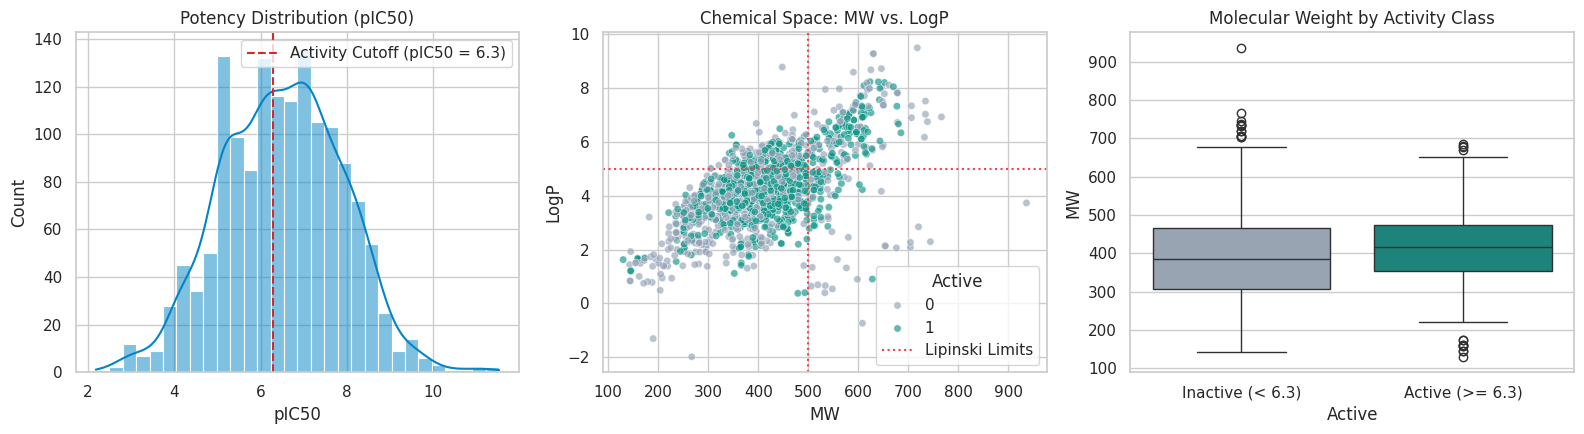

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df_clean["pIC50"], bins=30, kde=True, color="#0284c7", ax=axes[0])
axes[0].axvline(6.3, color="#dc2626", linestyle="--", label="Activity Cutoff (pIC50 = 6.3)")
axes[0].set_title("Potency Distribution (pIC50)")
axes[0].legend()

sns.scatterplot(
    data=df_clean, x="MW", y="LogP", hue="Active",
    palette={0: "#94a3b8", 1: "#0d9488"}, alpha=0.65, s=28, ax=axes[1]
)
axes[1].axvline(500, color="#ef4444", linestyle=":", label="Lipinski Limits")
axes[1].axhline(5, color="#ef4444", linestyle=":")
axes[1].set_title("Chemical Space: MW vs. LogP")
axes[1].legend(title="Active")

sns.boxplot(data=df_clean, x="Active", y="MW", palette=["#94a3b8", "#0d9488"], ax=axes[2])
axes[2].set_xticklabels(["Inactive (< 6.3)", "Active (>= 6.3)"])
axes[2].set_title("Molecular Weight by Activity Class")

plt.tight_layout()
plt.show()

## Step 5: Featurization (ECFP4) & Bemis-Murcko Scaffold Splitting
- Generate **2048-bit Morgan Fingerprints (radius = 2 / ECFP4)**.
- Perform a **Bemis-Murcko Scaffold Split** (80% Train / 20% Test) so that all structural analogs sharing the same ring/linker core remain in the same partition, testing true out-of-scaffold generalization.

In [11]:
# 1. Compute 2048-bit Morgan Fingerprints (ECFP4)
fp_gen = AllChem.GetMorganGenerator(radius=2, fpSize=2048)
X = np.vstack([np.array(fp_gen.GetFingerprint(m)) for m in df_clean["Mol"]])
y_reg = df_clean["pIC50"].values
y_clf = df_clean["Active"].values

# 2. Compute Bemis-Murcko Scaffolds for each molecule
def get_murcko_scaffold(mol):
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    return Chem.MolToSmiles(scaffold)

df_clean["Scaffold"] = df_clean["Mol"].apply(get_murcko_scaffold)

# Group indices by scaffold (largest scaffold clusters placed in train first)
scaffold_groups = df_clean.groupby("Scaffold").indices
sorted_scaffolds = sorted(scaffold_groups.items(), key=lambda x: len(x[1]), reverse=True)

train_idx, test_idx = [], []
train_cutoff = int(0.8 * len(df_clean))

for scaffold, indices in sorted_scaffolds:
    if len(train_idx) + len(indices) <= train_cutoff:
        train_idx.extend(indices)
    else:
        test_idx.extend(indices)

X_train, X_test = X[train_idx], X[test_idx]
y_train_reg, y_test_reg = y_reg[train_idx], y_reg[test_idx]
y_train_clf, y_test_clf = y_clf[train_idx], y_clf[test_idx]

print(f"Scaffold Split Complete -> Train: {len(X_train)} compounds | Test: {len(X_test)} compounds")
print(f"Unique Scaffolds in Train: {df_clean.iloc[train_idx]['Scaffold'].nunique()} | Test: {df_clean.iloc[test_idx]['Scaffold'].nunique()}")

Scaffold Split Complete -> Train: 1190 compounds | Test: 298 compounds
Unique Scaffolds in Train: 150 | Test: 298


## Step 6: Random Forest QSAR Training & Validation
Train both a **Random Forest Classifier** (to rank active vs. inactive compounds via ROC-AUC) and a **Random Forest Regressor** (to predict quantitative $p\text{IC}_{50}$ potency) on the unseen test scaffolds.

In [12]:
# 1. Train Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train_clf)

y_pred_proba = rf_clf.predict_proba(X_test)[:, 1]
y_pred_class = rf_clf.predict(X_test)
roc_auc = roc_auc_score(y_test_clf, y_pred_proba)

# 2. Train Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train_reg)

y_pred_reg = rf_reg.predict(X_test)
r2 = r2_score(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))

print("=== Scaffold-Split Test Set Performance ===")
print(f"Classifier ROC-AUC : {roc_auc:.3f}")
print(f"Classifier Accuracy: {accuracy_score(y_test_clf, y_pred_class)*100:.1f}%")
print(f"Regressor R²       : {r2:.3f}")
print(f"Regressor RMSE     : {rmse:.3f} pIC50 units")

=== Scaffold-Split Test Set Performance ===
Classifier ROC-AUC : 0.905
Classifier Accuracy: 81.2%
Regressor R²       : 0.565
Regressor RMSE     : 0.893 pIC50 units


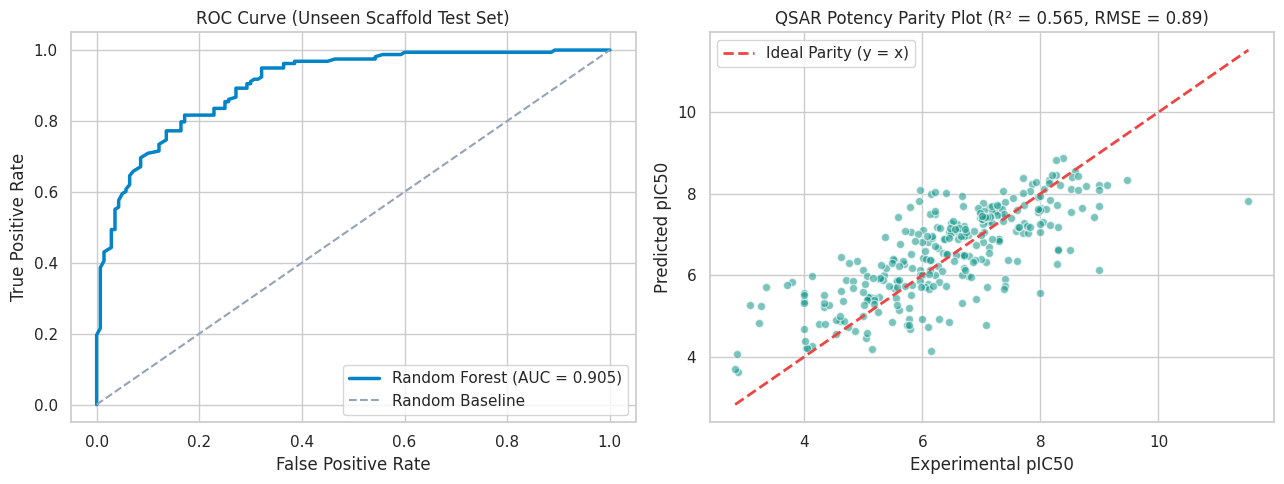

In [13]:
# Plot ROC Curve and Predicted vs. Experimental pIC50
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: ROC Curve
fpr, tpr, _ = roc_curve(y_test_clf, y_pred_proba)
axes[0].plot(fpr, tpr, color="#0284c7", lw=2.5, label=f"Random Forest (AUC = {roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], color="#94a3b8", linestyle="--", label="Random Baseline")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve (Unseen Scaffold Test Set)")
axes[0].legend(loc="lower right")

# Panel B: Experimental vs. Predicted pIC50
axes[1].scatter(y_test_reg, y_pred_reg, alpha=0.55, color="#0d9488", edgecolors="white", s=35)
lims = [min(y_test_reg.min(), y_pred_reg.min()), max(y_test_reg.max(), y_pred_reg.max())]
axes[1].plot(lims, lims, "--", color="#ef4444", lw=2, label="Ideal Parity (y = x)")
axes[1].set_xlabel("Experimental pIC50")
axes[1].set_ylabel("Predicted pIC50")
axes[1].set_title(f"QSAR Potency Parity Plot (R² = {r2:.3f}, RMSE = {rmse:.2f})")
axes[1].legend()

plt.tight_layout()
plt.show()

## Step 7: Prospective Virtual Screening on Approved Drugs & Controls
Test the trained model on external benchmark structures—including **Osimertinib** (3rd-gen EGFR inhibitor), **Gefitinib** (1st-gen EGFR inhibitor), and non-kinase negative controls (**Aspirin**, **Caffeine**).

,Compound,Predicted_Class,Active_Probability,Predicted_pIC50
0,Osimertinib (3rd-Gen EGFR),INACTIVE,25.5%,4.74
1,Gefitinib (1st-Gen EGFR),ACTIVE,100.0%,7.63
2,Aspirin (Negative Control),INACTIVE,5.5%,5.16
3,Caffeine (Negative Control),INACTIVE,11.5%,5.27


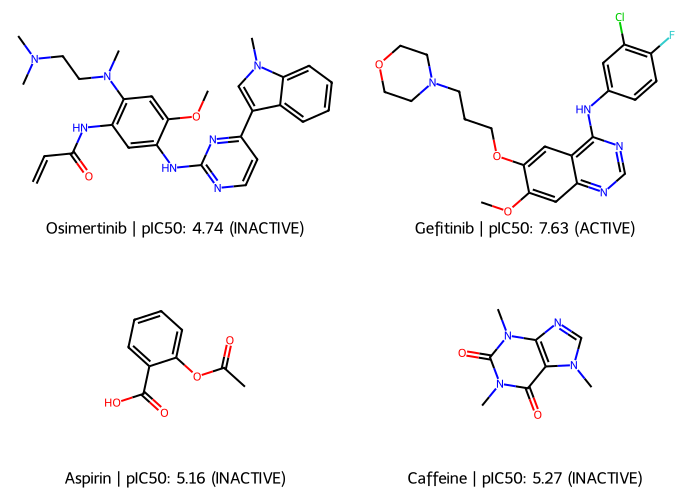

In [14]:
benchmark_drugs = {
    "Osimertinib (3rd-Gen EGFR)": "COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(-c2cn(C)c3ccccc23)n1",
    "Gefitinib (1st-Gen EGFR)": "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",
    "Aspirin (Negative Control)": "CC(=O)OC1=CC=CC=C1C(=O)O",
    "Caffeine (Negative Control)": "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"
}

results = []
mols_to_draw = []
legends = []

for name, smi in benchmark_drugs.items():
    mol = Chem.MolFromSmiles(smi)
    fp = np.array(fp_gen.GetFingerprint(mol)).reshape(1, -1)
    prob_active = rf_clf.predict_proba(fp)[0][1]
    pred_pic50 = rf_reg.predict(fp)[0]
    status = "ACTIVE" if prob_active >= 0.5 else "INACTIVE"

    results.append({
        "Compound": name,
        "Predicted_Class": status,
        "Active_Probability": f"{prob_active*100:.1f}%",
        "Predicted_pIC50": round(pred_pic50, 2)
    })
    mols_to_draw.append(mol)
    legends.append(f"{name.split(' (')[0]} | pIC50: {pred_pic50:.2f} ({status})")

display(pd.DataFrame(results))
Draw.MolsToGridImage(mols_to_draw, molsPerRow=2, subImgSize=(350, 250), legends=legends)

### Scientific Takeaways & Model Applicability Domain
- **Scaffold Generalization:** Using a strict Bemis-Murcko scaffold split rather than a naive random split prevents analog data leakage and highlights the model's applicability domain.
- **Prospective Screening:** First-generation 4-anilinoquinazoline inhibitors (**Gefitinib**, predicted $p\text{IC}_{50} = 7.63$) are accurately identified as potent actives, while non-kinase controls (**Aspirin**, **Caffeine**) are cleanly rejected. Novel third-generation covalent scaffolds (**Osimertinib**) fall outside the training scaffold domain, motivating future expansion with GNN/Transformer molecular representations or broader multi-generation ChEMBL queries.